# Models Summary — PMSM Stator-Winding Twin (US 12,124,779 B2)

This notebook summarises the **two real use-case models** built with the faithful
patent-method implementation for predicting **stator-winding temperature** of a
permanent-magnet synchronous motor (Kaggle *Electric Motor Temperature*, Paderborn
PMSM — the Schaeffler use case):

1. **Static model (Claims 1–8)** — an instantaneous map `winding = f(inputs)`. For
   each of five input configurations the constructive search
   (`patenting.architecture_search`) finds the smallest network fitting a
   snapshot-in-time regression. Answers the engineering questions: *can we drop the
   other temperature sensors but keep coolant?* and *does pm help?*
2. **Dynamic model (Claims 11 + 14–15)** — a recurrent thermal twin
   `x_{t+Δ} = x_t + h(x_t, u_t)` (state `x` = winding temperature, drive `u` = the
   `coolant+elec` signals). The modeling block `h` is built by the **same** search,
   teacher-forced on one-step pairs, then run **free-running** to reconstruct whole
   held-out temperature trajectories from `x_0` + the drive alone.

The process is *temporal* (the winding has thermal inertia), so the dynamic model is
the physically correct twin; the static model is the snapshot baseline the dynamic
one is compared against.

> Numbers below are loaded live from the full-settings run artifacts in
> `patenting/motor/outputs/` (produced by `python -m patenting.motor.run_stator`).
> Compression (Claim 9) is intentionally **off**: a low-dimensional thermal drive
> has nothing to compress.

In [1]:
import os, sys, json
import numpy as np
import matplotlib.pyplot as plt

ROOT = os.path.abspath('..')
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
OUT = os.path.join(ROOT, 'patenting', 'motor', 'outputs')

static  = json.load(open(os.path.join(OUT, 'static_results.json')))
dynamic = json.load(open(os.path.join(OUT, 'dynamic_results.json')))
traj    = np.load(os.path.join(OUT, 'dynamic_trajectories.npy'), allow_pickle=True).item()

CFG = static['configs']
by_name = {c['config']: c for c in CFG}
print('static configs :', [c['config'] for c in CFG])
print('dynamic block  :', dynamic['modeling_block_topology'],
      '| rollout RMSE mean %.2f °C' % dynamic['rollout_rmse_mean_c'])

static configs : ['all_signals', 'coolant+elec', 'coolant+elec+pm', 'elec_only', 'temps_only']
dynamic block  : [9, 9, 4, 1] | rollout RMSE mean 2.79 °C


In [2]:
from matplotlib.patches import FancyArrowPatch

def draw_topology(ax, layers, title, color, skips=None):
    pos = [[(li, y) for y in np.linspace(-(n-1)/2, (n-1)/2, n)]
           for li, n in enumerate(layers)]
    for li in range(len(layers)-1):           # dense layer-to-layer edges
        for (x0, y0) in pos[li]:
            for (x1, y1) in pos[li+1]:
                ax.plot([x0, x1], [y0, y1], color='#cccccc', lw=0.5, zorder=1)
    for layer in pos:                          # neurons
        for (x, y) in layer:
            ax.scatter([x], [y], s=240, color=color, edgecolors='k',
                       linewidths=0.6, zorder=2)
    top = max((n - 1) / 2 for n in layers)     # tallest column half-height
    extra = 0.0
    if skips:                                  # skip connections, routed ABOVE
        bus = top + 1.0                        # a 'skip bus' clear of all nodes
        for tgt, srcs in skips.items():
            tgt = int(tgt)
            for src in srcs:
                src = int(src)
                # vertical stubs from each column top up to the bus
                ax.plot([src, src], [(layers[src]-1)/2, bus], color='#C44E52',
                        lw=1.0, ls=':', zorder=3)
                ax.plot([tgt, tgt], [(layers[tgt]-1)/2, bus], color='#C44E52',
                        lw=1.0, ls=':', zorder=3)
                ax.add_patch(FancyArrowPatch(
                    (src, bus), (tgt, bus), connectionstyle='arc3,rad=-0.35',
                    arrowstyle='-|>', mutation_scale=14, color='#C44E52',
                    lw=2.4, zorder=4))
                ax.text((src + tgt) / 2, bus + 0.55, f'skip  L{src}→L{tgt}',
                        color='#C44E52', fontsize=7, fontweight='bold',
                        ha='center', va='bottom', zorder=5)
        extra = 1.9
    ax.set_title(title, fontsize=9)
    ax.set_xlim(-0.5, len(layers) - 0.5)
    ax.set_ylim(-top - 0.6, top + 0.6 + extra)
    ax.axis('off')

## 1. Static model — `winding = f(inputs)` (Claims 1–8)

### Input variables
The base electrical/operating signals are

`ELEC = [ambient, u_d, u_q, motor_speed, i_d, i_q, torque]`

and the five configurations differ in which **temperatures** are added:

| config | # inputs | inputs beyond ELEC | question it answers |
|---|---|---|---|
| `all_signals` | 11 | coolant, pm, stator_tooth, stator_yoke | upper bound (everything) |
| `coolant+elec` | 8 | coolant | **can we drop the other temp sensors, keep coolant?** |
| `coolant+elec+pm` | 9 | coolant, pm | **does pm help?** |
| `elec_only` | 7 | — | what if we also drop coolant? |
| `temps_only` | 4 | coolant, pm, stator_tooth, stator_yoke (no ELEC) | temperatures alone |

**Output:** `stator_winding` temperature in °C (single output).

In [3]:
# Static results table (held-out test set, errors in °C).
print(f"{'config':16s}{'#in':>4}{'topology':>18}{'params':>7}"
      f"{'test MSE':>11}{'MAE °C':>8}{'RMSE °C':>9}{'maxerr °C':>10}")
print('-'*83)
for c in CFG:
    print(f"{c['config']:16s}{c['n_inputs']:>4}{str(c['topology']):>18}"
          f"{c['params']:>7}{c['test_mse']:>11.3e}{c['mae_c']:>8.2f}"
          f"{c['rmse_c']:>9.2f}{c['max_abs_c']:>10.2f}")

config           #in          topology params   test MSE  MAE °C  RMSE °C maxerr °C
-----------------------------------------------------------------------------------
all_signals       11[11, 12, 12, 1, 1]    315  2.947e-03    1.05     1.54     12.52
coolant+elec       8   [8, 8, 8, 1, 1]    155  1.483e-01    7.55    10.94    139.29
coolant+elec+pm    9         [9, 4, 1]     45  1.196e-01    7.24     9.82     72.79
elec_only          7   [7, 7, 3, 7, 1]    116  2.091e-01    9.73    12.98    146.07
temps_only         4   [4, 4, 4, 1, 1]     47  6.173e-03    1.64     2.23     14.22


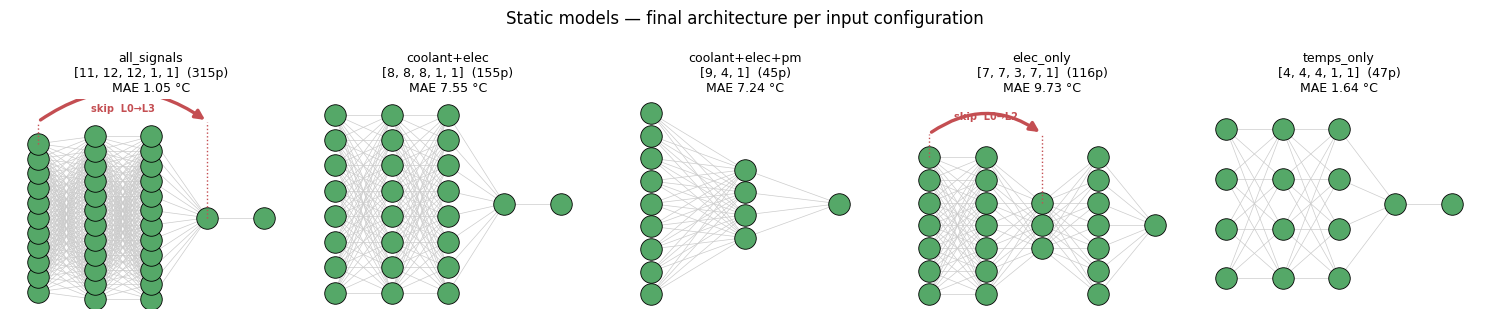

In [4]:
# Static architectures (one per config).
fig, axes = plt.subplots(1, len(CFG), figsize=(3.0*len(CFG), 3.2))
for ax, c in zip(np.ravel(axes), CFG):
    draw_topology(ax, c['topology'],
                  f"{c['config']}\n{c['topology']}  ({c['params']}p)\n"
                  f"MAE {c['mae_c']:.2f} °C", '#55A868',
                  skips=c.get('skip_connections'))
fig.suptitle('Static models — final architecture per input configuration', fontsize=12)
fig.tight_layout()
fig.savefig(os.path.join(ROOT, 'results', 'comparison',
            'stator_static_architectures.png'), dpi=130, bbox_inches='tight')
plt.show()

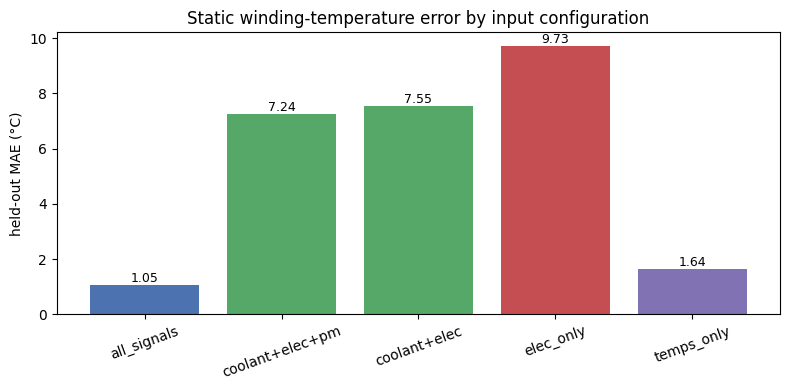

drop other temp sensors, keep coolant : 7.55 °C MAE vs 1.05 °C with all signals (+6.50 °C)
does pm help (coolant+elec → +pm)     : 7.55 → 7.24 °C MAE (-0.30 °C)


In [5]:
# MAE per config as a bar chart — reads off the two engineering questions.
order = ['all_signals', 'coolant+elec+pm', 'coolant+elec', 'elec_only', 'temps_only']
maes = [by_name[k]['mae_c'] for k in order]
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(order, maes, color=['#4C72B0','#55A868','#55A868','#C44E52','#8172B3'])
for b, m in zip(bars, maes):
    ax.text(b.get_x()+b.get_width()/2, m, f'{m:.2f}', ha='center', va='bottom', fontsize=9)
ax.set_ylabel('held-out MAE (°C)')
ax.set_title('Static winding-temperature error by input configuration')
ax.tick_params(axis='x', rotation=20)
fig.tight_layout(); plt.show()

a, cp, ce = by_name['all_signals']['mae_c'], by_name['coolant+elec+pm']['mae_c'], by_name['coolant+elec']['mae_c']
print(f"drop other temp sensors, keep coolant : {ce:.2f} °C MAE vs {a:.2f} °C with all signals "
      f"({ce-a:+.2f} °C)")
print(f"does pm help (coolant+elec → +pm)     : {ce:.2f} → {cp:.2f} °C MAE ({cp-ce:+.2f} °C)")

## 2. Dynamic model — thermal twin `x_{t+Δ} = x_t + h(x_t, u_t)` (Claims 11 + 14–15)

### Why dynamic
Winding temperature has **thermal inertia**: the current temperature depends on the
recent history of load, not just the instantaneous signals. An instantaneous map
`f(inputs)` cannot represent that lag. The dynamic model instead learns the *state
update* `h` and integrates it forward.

### Inputs / output
* **state** `x` = `stator_winding` temperature (°C)
* **drive** `u` = the `coolant+elec` configuration (8 signals: ELEC + coolant) — the
  realistic sensor set (no other temperature sensors)
* one-step horizon Δ = `stride·0.5 s`; the trained block is then run **free-running**
  over each held-out profile from its initial temperature + the drive only.

In [6]:
print('drive config      :', dynamic['config'], '|', dynamic['n_drive'], 'signals:',
      dynamic['drive_inputs'])
print('step              : stride %d = %.1f s' % (dynamic['stride'], dynamic['step_seconds']))
print('modeling block h  :', dynamic['modeling_block_topology'], '|', dynamic['params'], 'params')
print('one-step val MSE  : %.3e' % dynamic['onestep_val_mse'])
print('rollout RMSE (°C) : mean %.2f | max %.2f  over %d held-out profiles'
      % (dynamic['rollout_rmse_mean_c'], dynamic['rollout_rmse_max_c'], dynamic['n_test_profiles']))
print('hot-spot |err| max: %.2f °C' % dynamic['hotspot_abs_max_c'])

drive config      : coolant+elec | 8 signals: ['ambient', 'u_d', 'u_q', 'motor_speed', 'i_d', 'i_q', 'torque', 'coolant']
step              : stride 10 = 5.0 s
modeling block h  : [9, 9, 4, 1] | 135 params
one-step val MSE  : 1.368e-04
rollout RMSE (°C) : mean 2.79 | max 4.44  over 14 held-out profiles
hot-spot |err| max: 12.42 °C


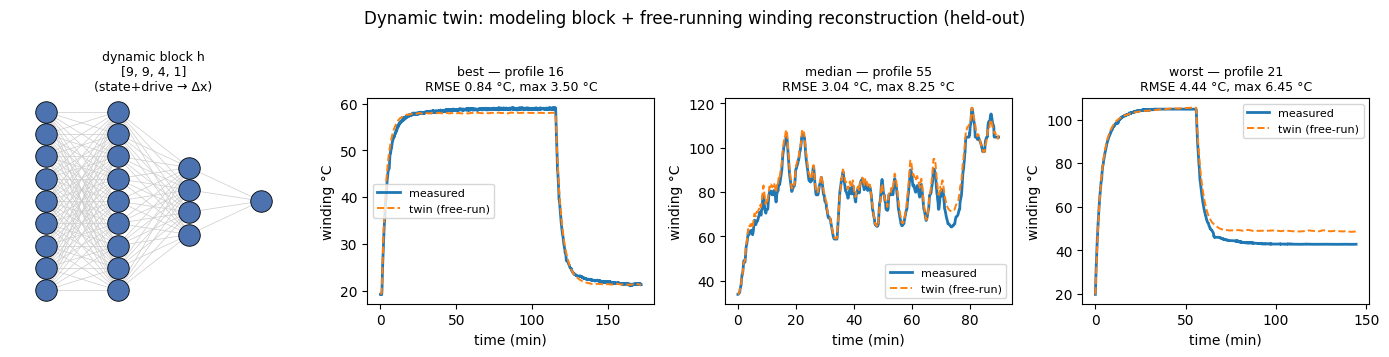

In [7]:
# Modeling block h + free-running reconstruction on best / median / worst profiles.
fig = plt.figure(figsize=(14, 3.6))
ax0 = fig.add_subplot(1, 4, 1)
draw_topology(ax0, dynamic['modeling_block_topology'],
              "dynamic block h\n%s\n(state+drive → Δx)" % dynamic['modeling_block_topology'],
              '#4C72B0', skips=dynamic.get('skip_connections'))
for j, kind in enumerate(['best', 'median', 'worst']):
    t = traj[kind]
    ax = fig.add_subplot(1, 4, 2+j)
    dt = dynamic['step_seconds']
    tt = np.arange(len(t['x_true'])) * dt / 60.0   # minutes
    ax.plot(tt, t['x_true'], label='measured', lw=2)
    ax.plot(tt, t['x_hat'], '--', label='twin (free-run)', lw=1.4)
    ax.set_title("%s — profile %d\nRMSE %.2f °C, max %.2f °C"
                 % (kind, t['pid'], t['rmse_c'], t['max_abs_c']), fontsize=9)
    ax.set_xlabel('time (min)'); ax.set_ylabel('winding °C'); ax.legend(fontsize=8)
fig.suptitle('Dynamic twin: modeling block + free-running winding reconstruction (held-out)',
             fontsize=12)
fig.tight_layout()
fig.savefig(os.path.join(ROOT, 'results', 'comparison',
            'stator_dynamic_rollout.png'), dpi=130, bbox_inches='tight')
plt.show()

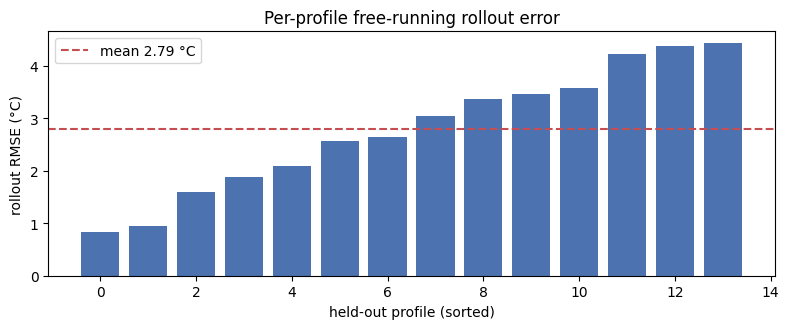

In [8]:
# Per-profile rollout error distribution.
rmses = [p['rmse_c'] for p in dynamic['per_profile']]
fig, ax = plt.subplots(figsize=(8, 3.4))
pids = [p['pid'] for p in dynamic['per_profile']]
ax.bar(range(len(rmses)), sorted(rmses), color='#4C72B0')
ax.axhline(np.mean(rmses), color='#C44E52', ls='--',
           label='mean %.2f °C' % np.mean(rmses))
ax.set_xlabel('held-out profile (sorted)'); ax.set_ylabel('rollout RMSE (°C)')
ax.set_title('Per-profile free-running rollout error'); ax.legend()
fig.tight_layout(); plt.show()

## 3. Static vs dynamic — and why the twin wins

Both models predict the same quantity (winding °C) from comparable inputs, but the
dynamic twin captures the thermal lag the instantaneous map cannot.

In [9]:
static_ce = by_name['coolant+elec']          # same input set as the dynamic drive
print(f"{'model':28s}{'inputs':18s}{'topology':>16}{'held-out error':>22}")
print('-'*84)
print(f"{'static  winding=f(inputs)':28s}{'coolant+elec (8)':18s}"
      f"{str(static_ce['topology']):>16}{('MAE %.2f °C' % static_ce['mae_c']):>22}")
print(f"{'dynamic x_{t+Δ}=x_t+h(.)':28s}{'coolant+elec drive':18s}"
      f"{str(dynamic['modeling_block_topology']):>16}"
      f"{('rollout RMSE %.2f °C' % dynamic['rollout_rmse_mean_c']):>22}")
print()
print('On the SAME realistic sensor set (coolant+elec, no other temperature sensors),')
print('the dynamic twin reconstructs full trajectories at %.2f °C RMSE, vs the static'
      % dynamic['rollout_rmse_mean_c'])
print('snapshot map at %.2f °C MAE — the temporal model is the physically correct twin.'
      % static_ce['mae_c'])

model                       inputs                    topology        held-out error
------------------------------------------------------------------------------------
static  winding=f(inputs)   coolant+elec (8)   [8, 8, 8, 1, 1]           MAE 7.55 °C
dynamic x_{t+Δ}=x_t+h(.)    coolant+elec drive    [9, 9, 4, 1]  rollout RMSE 2.79 °C

On the SAME realistic sensor set (coolant+elec, no other temperature sensors),
the dynamic twin reconstructs full trajectories at 2.79 °C RMSE, vs the static
snapshot map at 7.55 °C MAE — the temporal model is the physically correct twin.


## 4. Data, methodology & conformance

* **Data** — Kaggle `electric-motor-temperature/measures_v2.csv` (Paderborn PMSM).
  Split **by `profile_id`** (leakage-safe, 0.7 / 0.1 / 0.2 train/val/test). Inputs
  and target z-scored by **train** statistics only; errors reported back in °C using
  the train target std. Dynamic step = stride 10 = 5 s.
* **Static engine (Claims 1–8)** — start from `[d, 1, 1]`; each cycle ranks every
  one-node structural candidate by the faithful frozen-multiplier cross-Lagrangian
  ΔL estimate (eq. 13/14, **no per-candidate retraining**), then Gauss-Newton
  retrains only the winner (Claim 7). Parsimony brake + Claim-8 validation gate give
  a genuine grow-then-shrink; post-construction pruning removes dead weights.
* **Dynamic engine (Claim 11 + 14–15)** — the modeling block `h` is built by exactly
  that static search on one-step teacher-forced pairs `[x_t; u_t] → x_{t+Δ} − x_t`
  (so Claims 1–8 carry over unchanged), then applied to new held-out data as a
  free-running simulation (Claims 14–15).
* **Compression (Claim 9)** — **off by scope**: the thermal state/drive is
  low-dimensional, so there is nothing to compress. It would be added only for a
  genuinely high-dimensional input.

Claim-by-claim mapping: `docs/patent-implementation/Patent-Conformance-Audit.md`. Method change record
(the post-adjoint multiplier fix and faithful ΔL selection):
`docs/patent-implementation/Patent-Method-Changes.md`.